In [1]:
!pip install xgboost shap --quiet
!pip install statsmodels --quiet
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import xgboost as xgb
import shap
import pickle
import joblib
import warnings

from datetime import datetime
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (train_test_split, StratifiedKFold,
                                      cross_val_score, RandomizedSearchCV)
from sklearn.cluster import KMeans
from sklearn.metrics import (roc_auc_score, classification_report,
                              confusion_matrix, silhouette_score, roc_curve)
from sklearn.linear_model import LogisticRegression

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', None)

print("All libraries loaded successfully!")


All libraries loaded successfully!


In [2]:
# ── LOAD DATA ─────────────────────────────────────────────────────────

df = pd.read_csv("/content/marketing_campaign.csv", sep="\t")

print("Dataset loaded")
print("Number of customers:", df.shape[0])
print("Number of columns:  ", df.shape[1])
df.head()


Dataset loaded
Number of customers: 2240
Number of columns:   29


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,MntFruits,MntMeatProducts,MntFishProducts,MntSweetProducts,MntGoldProds,NumDealsPurchases,NumWebPurchases,NumCatalogPurchases,NumStorePurchases,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,88,546,172,88,88,3,8,10,4,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,1,6,2,1,6,2,1,1,2,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,49,127,111,21,42,1,8,2,10,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,4,20,10,3,5,2,2,0,4,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,43,118,46,27,15,5,5,3,6,5,0,0,0,0,0,0,3,11,0


In [3]:
print(df.shape)
print(df.columns.tolist())

(2240, 29)
['ID', 'Year_Birth', 'Education', 'Marital_Status', 'Income', 'Kidhome', 'Teenhome', 'Dt_Customer', 'Recency', 'MntWines', 'MntFruits', 'MntMeatProducts', 'MntFishProducts', 'MntSweetProducts', 'MntGoldProds', 'NumDealsPurchases', 'NumWebPurchases', 'NumCatalogPurchases', 'NumStorePurchases', 'NumWebVisitsMonth', 'AcceptedCmp3', 'AcceptedCmp4', 'AcceptedCmp5', 'AcceptedCmp1', 'AcceptedCmp2', 'Complain', 'Z_CostContact', 'Z_Revenue', 'Response']


In [4]:
#DATA CLEANING AND UNDERSTANDING

print("MISSING VALUES PER COLUMN:")
print(df.isnull().sum())

# 1. Remove rows with missing Income
df = df.dropna(subset=['Income']).copy()
print(f"\nAfter removing missing income rows: {df.shape}")

# 2. Fix date column (convert string to proper datetime)
df['Dt_Customer'] = pd.to_datetime(df['Dt_Customer'], format='%d-%m-%Y')

# 3. Create Age column
# Use a reference date anchored to the dataset's own timeframe, not today's date
reference_date = df['Dt_Customer'].max()   # or datetime(2014, 12, 31) if you want a fixed cutoff
df['Age'] = reference_date.year - df['Year_Birth']

# 4. Remove outliers — implausible ages and extreme incomes
#    The marketing_campaign dataset is known to contain birth years like 1893.
#    These are data entry errors and must be removed before analysis.
print(f"\nOutliers detected:")
print(f"  Customers with Age > 90:         {(df['Age'] > 90).sum()}")
print(f"  Customers with Income > 200,000: {(df['Income'] > 200000).sum()}")

df = df[(df['Age'] <= 90) & (df['Income'] <= 200000)].copy()
print(f"\nShape after outlier removal: {df.shape}")

# 5. Simplify Marital Status (collapse rare/nonsensical categories)
df['Marital_Status'] = df['Marital_Status'].replace(
    ['Absurd', 'Alone', 'Widow', 'YOLO'], 'Single'
)

# 6. Create Total_Kids
df['Total_Kids'] = df['Kidhome'] + df['Teenhome']

# 7. Days as customer
df['Days_As_Customer'] = (reference_date - df['Dt_Customer']).dt.days

print("\nData cleaning completed!")
print("Final shape:", df.shape)
print("\nMarital Status distribution:")
print(df['Marital_Status'].value_counts())
print("\nSample of cleaned data:")
display(df[['Age', 'Income', 'Marital_Status', 'Total_Kids', 'Days_As_Customer']].head(10))

MISSING VALUES PER COLUMN:
ID                      0
Year_Birth              0
Education               0
Marital_Status          0
Income                 24
Kidhome                 0
Teenhome                0
Dt_Customer             0
Recency                 0
MntWines                0
MntFruits               0
MntMeatProducts         0
MntFishProducts         0
MntSweetProducts        0
MntGoldProds            0
NumDealsPurchases       0
NumWebPurchases         0
NumCatalogPurchases     0
NumStorePurchases       0
NumWebVisitsMonth       0
AcceptedCmp3            0
AcceptedCmp4            0
AcceptedCmp5            0
AcceptedCmp1            0
AcceptedCmp2            0
Complain                0
Z_CostContact           0
Z_Revenue               0
Response                0
dtype: int64

After removing missing income rows: (2216, 29)

Outliers detected:
  Customers with Age > 90:         3
  Customers with Income > 200,000: 1

Shape after outlier removal: (2212, 30)

Data cleaning complete

,Age,Income,Marital_Status,Total_Kids,Days_As_Customer
0,57,58138.0,Single,0,663
1,60,46344.0,Single,2,113
2,49,71613.0,Together,0,312
3,30,26646.0,Together,1,139
4,33,58293.0,Married,1,161
5,47,62513.0,Together,1,293
6,43,55635.0,Divorced,1,593
7,29,33454.0,Married,1,417
8,40,30351.0,Together,1,388
9,64,5648.0,Together,2,108


In [5]:
# ── FEATURE ENGINEERING ───────────────────────────────────────────────

# 1. RFM Features (core customer value metrics)
#    Recency is already in the dataset (days since last purchase)
# Frequency now excludes NumDealsPurchases: diagnostic checks (see thesis Methodology)
# found that NumDealsPurchases essentially never exceeds total channel purchases (99.9%
# of customers), consistent with — though not conclusive proof of — deals purchases
# occurring through, rather than separately from, the three channels below. The
# conservative choice is to exclude it from Frequency to avoid any risk of double-counting.
df['Frequency'] = df['NumWebPurchases'] + df['NumCatalogPurchases'] + df['NumStorePurchases']

# NumDealsPurchases is retained as its own separate behavioral feature

df['Monetary'] = (df['MntWines'] + df['MntFruits'] + df['MntMeatProducts'] +
                  df['MntFishProducts'] + df['MntSweetProducts'] + df['MntGoldProds'])
# 2. Green Preference Features
#    NOTE: Only Fruits and Fish are used as sustainable/eco-friendly proxies.
#    Meat is intentionally EXCLUDED: meat production has one of the highest
#    carbon footprints of any food category, which directly contradicts
#    sustainability principles (Poore & Nemecek, 2018, Science).
df['Green_Score'] = df['MntFruits'] + df['MntFishProducts']

# Green_Ratio no longer uses a "+1" safeguard in the denominator: descriptive
# statistics confirm no customer has zero Monetary spend (min = 5.00), so the
# safeguard was unnecessary and was slightly distorting the ratio, particularly
# for low-spending customers.
assert (df['Monetary'] == 0).sum() == 0, "Cannot remove +1 safeguard: some customers have zero Monetary spend"
df['Green_Ratio'] = df['Green_Score'] / df['Monetary']

# Verify Green_Ratio is correctly bounded between 0 and 1
assert df['Green_Ratio'].max() <= 1.0, "Green_Ratio should be <= 1.0"
assert df['Green_Ratio'].min() >= 0.0, "Green_Ratio should be >= 0.0"
print(f"Green_Ratio range: {df['Green_Ratio'].min():.4f} — {df['Green_Ratio'].max():.4f} ")


# 3. Campaign engagement
df['Total_Accepted_Campaigns'] = (df['AcceptedCmp1'] + df['AcceptedCmp2'] +
                                   df['AcceptedCmp3'] + df['AcceptedCmp4'] +
                                   df['AcceptedCmp5'])


Green_Ratio range: 0.0000 — 0.6154 


In [6]:
# ── DIAGNOSTIC: Does NumDealsPurchases overlap with other channels? ──

# Check 1: Does NumDealsPurchases ever exceed the sum of the other three channels?
# If deals were a fully separate channel, this would be a nonsensical outlier;
# if deals are a SUBSET of other channels, NumDealsPurchases should never exceed them.
channel_sum = df['NumWebPurchases'] + df['NumCatalogPurchases'] + df['NumStorePurchases']
deals_exceeds_channels = (df['NumDealsPurchases'] > channel_sum).sum()
print(f"Customers where NumDealsPurchases > (Web+Catalog+Store): {deals_exceeds_channels} "
      f"({deals_exceeds_channels/len(df)*100:.1f}%)")

# Check 2: Correlation between NumDealsPurchases and total channel purchases
corr_deals_channels = df['NumDealsPurchases'].corr(channel_sum)
print(f"Correlation between NumDealsPurchases and total channel purchases: {corr_deals_channels:.3f}")

# Check 3: Descriptive comparison
print("\nNumDealsPurchases summary:")
print(df['NumDealsPurchases'].describe())
print("\nTotal channel purchases (Web+Catalog+Store) summary:")
print(channel_sum.describe())

# Check 4: What % of customers have zero deals purchases but nonzero channel purchases?
# (would support deals being a subset, since most customers would have channel activity
# regardless of whether they used a discount)
zero_deals_nonzero_channels = ((df['NumDealsPurchases'] == 0) & (channel_sum > 0)).sum()
print(f"\nCustomers with 0 deals but >0 channel purchases: {zero_deals_nonzero_channels} "
      f"({zero_deals_nonzero_channels/len(df)*100:.1f}%)")

Customers where NumDealsPurchases > (Web+Catalog+Store): 3 (0.1%)
Correlation between NumDealsPurchases and total channel purchases: 0.117

NumDealsPurchases summary:
count    2212.000000
mean        2.324593
std         1.924507
min         0.000000
25%         1.000000
50%         2.000000
75%         3.000000
max        15.000000
Name: NumDealsPurchases, dtype: float64

Total channel purchases (Web+Catalog+Store) summary:
count    2212.000000
mean       12.566908
std         7.205427
min         0.000000
25%         6.000000
50%        12.000000
75%        18.250000
max        32.000000
dtype: float64

Customers with 0 deals but >0 channel purchases: 40 (1.8%)


In [7]:

# 4. Churn Label
#    IMPORTANT — DATA LEAKAGE FIX:
#    Churn is now defined using ONLY Recency (days since last purchase).
#    The original version also used Total_Accepted_Campaigns == 0, which caused
#    data leakage: the model would then trivially learn that a feature (campaigns)
#    with value 0 always means Churn = 1, artificially inflating the AUC score.
#    Using only Recency > 90 days gives a clean, interpretable, leakage-free label.

# Churn label: single-signal definition (Recency only) to avoid leakage.
# See note above — Frequency/Campaigns were removed from this formula
# because they were also used as model features downstream.
df['Churn'] = (df['Recency'] > 90).astype(int)

print(f"New Churn Rate:      {df['Churn'].mean():.1%}")
print(f"Churned customers:   {df['Churn'].sum()}")

# Summary
print("\nFEATURE ENGINEERING SUMMARY")

print(f"  Churn Rate (Recency > 90 days, leakage-free): {df['Churn'].mean():.1%}")
print(f"  Average Green Ratio:            {df['Green_Ratio'].mean():.4f}")
print(f"  Customers with 0 campaigns:     {(df['Total_Accepted_Campaigns'] == 0).sum()}")
print(f"  Average campaigns accepted:     {df['Total_Accepted_Campaigns'].mean():.2f}")

print("\nSample of engineered features:")
display(df[['Recency', 'Frequency', 'Monetary', 'Green_Score', 'Green_Ratio',
            'Total_Accepted_Campaigns', 'Churn']].head(8))

df.to_csv('customers_with_features.csv', index=False)
print("\nFeature engineering complete. Saved as 'customers_with_features.csv'")


New Churn Rate:      8.8%
Churned customers:   194

FEATURE ENGINEERING SUMMARY
  Churn Rate (Recency > 90 days, leakage-free): 8.8%
  Average Green Ratio:            0.1211
  Customers with 0 campaigns:     1754
  Average campaigns accepted:     0.30

Sample of engineered features:


,Recency,Frequency,Monetary,Green_Score,Green_Ratio,Total_Accepted_Campaigns,Churn
0,58,22,1617,260,0.160792,0,0
1,38,4,27,3,0.111111,0,0
2,26,20,776,160,0.206186,0,0
3,26,6,53,14,0.264151,0,0
4,94,14,422,89,0.210900,0,1
5,16,20,716,42,0.058659,0,0
6,34,17,590,115,0.194915,0,0
7,32,8,169,13,0.076923,0,0



Feature engineering complete. Saved as 'customers_with_features.csv'


In [8]:
# Threshold Sensitivity Analysis
# Checks whether the churn/inactivity findings depend on the specific 90-day cutoff

thresholds = [60, 75, 90]
sensitivity_results = []

for threshold in thresholds:
    temp_churn = (df['Recency'] > threshold).astype(int)
    n_inactive = temp_churn.sum()
    pct_inactive = n_inactive / len(df) * 100
    corr = df['Green_Ratio'].corr(temp_churn)

    sensitivity_results.append({
        'Threshold': f'>{threshold} days',
        'N_Inactive': n_inactive,
        'Pct_Inactive': round(pct_inactive, 1),
        'Correlation_with_Green_Ratio': round(corr, 4)
    })

sensitivity_df = pd.DataFrame(sensitivity_results)
print(sensitivity_df.to_string(index=False))

Threshold  N_Inactive  Pct_Inactive  Correlation_with_Green_Ratio
 >60 days         849          38.4                       -0.0364
 >75 days         524          23.7                       -0.0026
 >90 days         194           8.8                       -0.0046


STATISTICAL SUMMARY OF KEY FEATURES
           Age     Income  Recency  Frequency  Monetary  Green_Ratio  \
count  2212.00    2212.00  2212.00    2212.00   2212.00      2212.00   
mean     45.09   51958.81    49.02      12.57    607.27         0.12   
std      11.70   21527.28    28.94       7.21    602.51         0.11   
min      18.00    1730.00     0.00       0.00      5.00         0.00   
25%      37.00   35233.50    24.00       6.00     69.00         0.04   
50%      44.00   51371.00    49.00      12.00    397.00         0.09   
75%      55.00   68487.00    74.00      18.25   1048.00         0.18   
max      74.00  162397.00    99.00      32.00   2525.00         0.62   

       Total_Kids  Days_As_Customer    Churn  
count     2212.00           2212.00  2212.00  
mean         0.95            353.71     0.09  
std          0.75            202.49     0.28  
min          0.00              0.00     0.00  
25%          0.00            180.00     0.00  
50%          1.00            356.


BUSINESS QUESTION 3: How does income affect churn and green buying?
              Green_Ratio  Churn_Rate  Avg_Spend  Customer_Count
Income_Level                                                    
Low                 0.189       0.085     81.627             553
Medium-Low          0.090       0.099    231.018             553
Medium-High         0.089       0.065    758.412             554
High                0.117       0.101   1359.101             552

Note: Churn rate does not vary monotonically with Income_Level under the
corrected label — no clear income-churn trend is evident in this data.



BUSINESS QUESTION 4: Which features correlate most with churn?


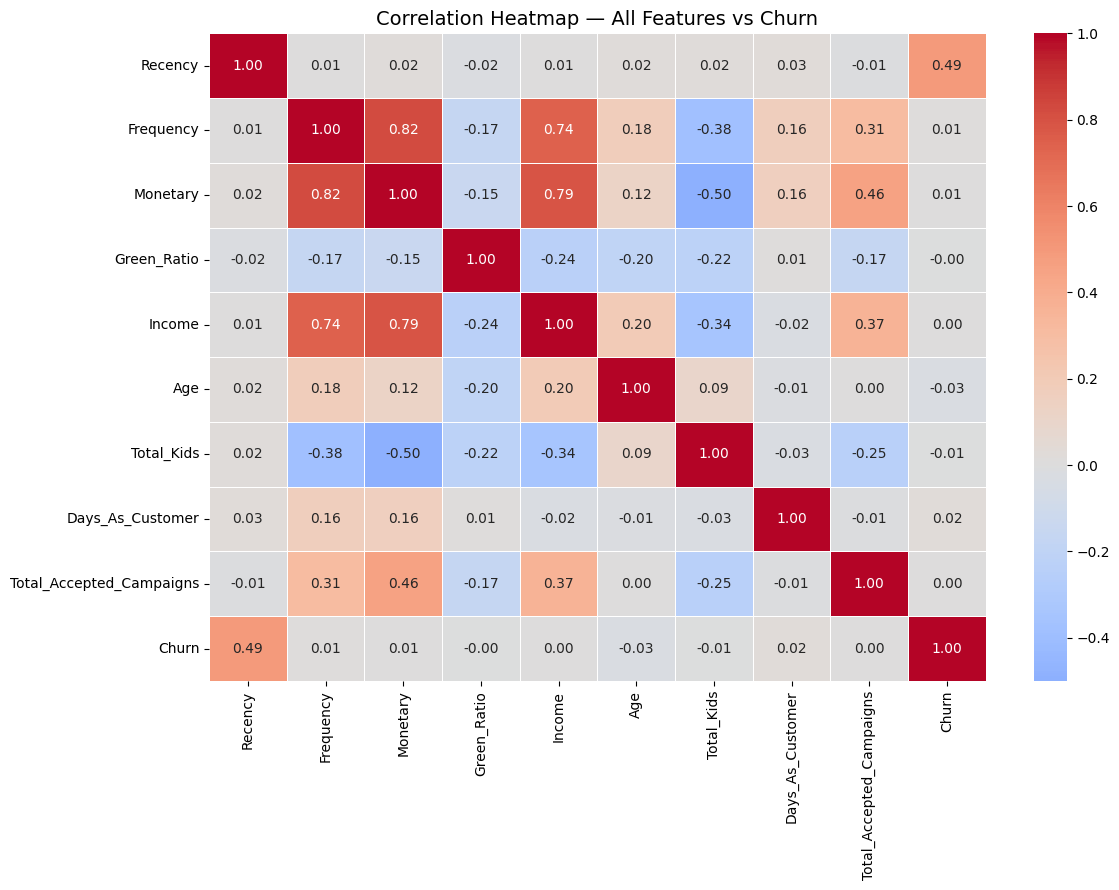

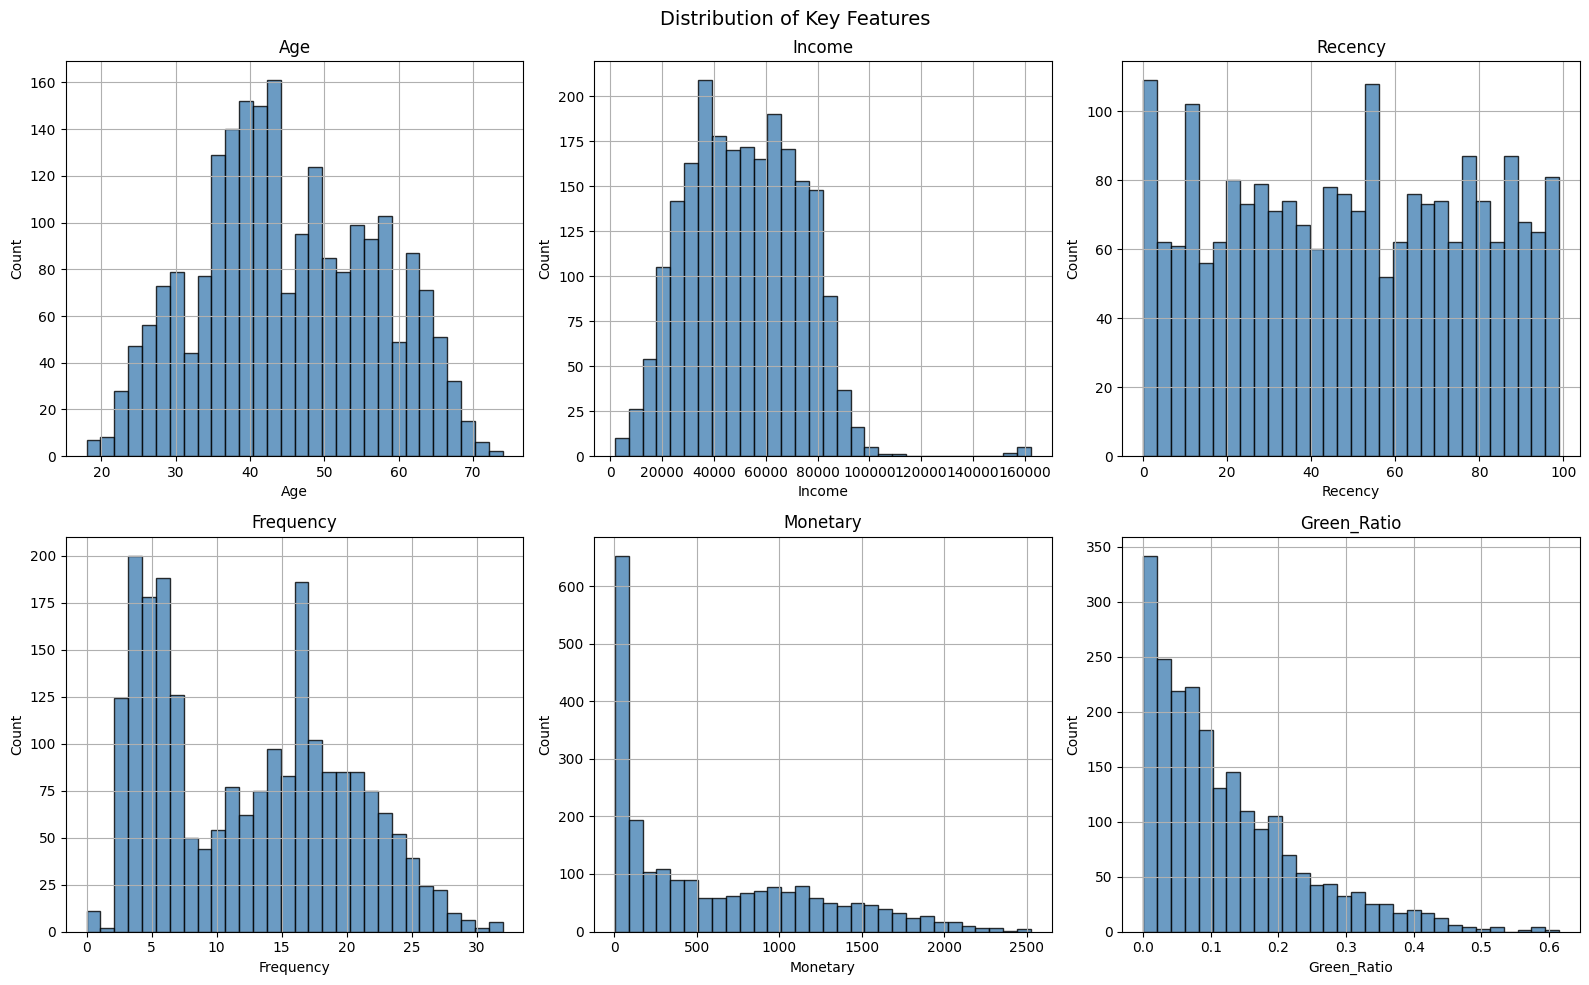


EDA complete. Saved as 'customers_with_eda.csv'


In [9]:
# ──  EXPLORATORY DATA ANALYSIS (EDA) ───────────────────────────────────

# 1. Statistical Summary
print("STATISTICAL SUMMARY OF KEY FEATURES")
key_features = ['Age', 'Income', 'Recency', 'Frequency', 'Monetary',
                 'Green_Ratio', 'Total_Kids', 'Days_As_Customer', 'Churn']
print(df[key_features].describe().round(2))

# 2. Overall Churn Rate
print(f"\nBUSINESS QUESTION 1: Overall churn rate?")
print(f"  {df['Churn'].mean():.1%} of customers are flagged as churned/at-risk")
print(f"  Definition: Recency > 90 days (single-signal, leakage-free)")
print(f"  That is {df['Churn'].sum()} out of {len(df)} customers")

# 3. Green Level Bucketing
#    FIXED: With Green_Ratio now correctly bounded between 0 and 1,
#    these bins are valid and will not produce NaN values.

df['Green_Level'] = pd.cut(
    df['Green_Ratio'],
    bins=[-0.001, 0.10, 0.25, 1.0],
    labels=['Low Green', 'Medium Green', 'High Green']
)

# Quick sanity check - verify new churn correlates with features
print("\nCORRELATION CHECK — New Churn vs Features:")
check_features = ['Income', 'Frequency', 'Monetary', 'Green_Ratio',
                  'Total_Accepted_Campaigns', 'Recency', 'Age', 'Churn']
corr_with_churn = df[check_features].corr()['Churn'].sort_values()
print(corr_with_churn.round(3))

print("\nNote: after removing Frequency/Campaigns from the Churn formula,")
print("these correlations should now reflect genuine behavioral relationships,")
print("not the label's own construction.")

print(f"\nGreen Level Distribution:")
print(df['Green_Level'].value_counts())
print(f"NaN values in Green_Level: {df['Green_Level'].isnull().sum()}")  # Should be 0

# 4. Churn Rate by Green Level
print("\nBUSINESS QUESTION 2: Do green customers churn less?")
green_churn = df.groupby('Green_Level', observed=True)['Churn'].mean().round(3)
print(green_churn)

print("\nUPDATE: With the corrected (leakage-free) Churn label, the earlier 'High Green")
print("= more churn' pattern disappears. Churn rates across Green levels are now nearly")
print("identical (9.4% / 8.0% / 8.0%), and Green_Ratio's correlation with Churn is")
print("~0.00. Conclusion: green preference shows no meaningful relationship with churn")
print("in this corrected analysis.")
print("See Income_Level table below for further context on Income's relationship")
print("with churn and green spending (tested formally in a later section).")

fig1 = px.bar(
    green_churn.reset_index(),
    x='Green_Level', y='Churn',
    title='Churn Rate by Green Spending Level (Sustainability Insight)',
    labels={'Churn': 'Churn Rate'},
    color='Churn',
    text_auto='.1%',
    color_continuous_scale='RdYlGn_r'
)
fig1.update_layout(yaxis_tickformat='.0%')
fig1.show()

# 5. Income Level Analysis
print("\nBUSINESS QUESTION 3: How does income affect churn and green buying?")
df['Income_Level'] = pd.qcut(
    df['Income'], q=4,
    labels=['Low', 'Medium-Low', 'Medium-High', 'High']
)

income_analysis = df.groupby('Income_Level', observed=True).agg(
    Green_Ratio=('Green_Ratio', 'mean'),
    Churn_Rate=('Churn', 'mean'),
    Avg_Spend=('Monetary', 'mean'),
    Customer_Count=('Churn', 'count')
).round(3)
print(income_analysis)

print("\nNote: Churn rate does not vary monotonically with Income_Level under the")
print("corrected label — no clear income-churn trend is evident in this data.")

fig2 = px.scatter(
    df, x='Income', y='Green_Ratio',
    color='Churn',
    title='Income vs Green Ratio (colored by Churn Status)',
    labels={'Green_Ratio': 'Green Spending Ratio'},
    color_continuous_scale='RdYlGn_r',
    opacity=0.6
)
fig2.show()

# 6. Correlation Heatmap
print("\nBUSINESS QUESTION 4: Which features correlate most with churn?")
corr_features = ['Recency', 'Frequency', 'Monetary', 'Green_Ratio',
                  'Income', 'Age', 'Total_Kids', 'Days_As_Customer',
                  'Total_Accepted_Campaigns', 'Churn']
corr_matrix = df[corr_features].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0,
            fmt='.2f', linewidths=0.5)
plt.title('Correlation Heatmap — All Features vs Churn', fontsize=14)
plt.tight_layout()
plt.show()

# 7. Distribution Plots for Key Features
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
fig.suptitle('Distribution of Key Features', fontsize=14)

for ax, col in zip(axes.flatten(),
                   ['Age', 'Income', 'Recency', 'Frequency', 'Monetary', 'Green_Ratio']):
    df[col].hist(bins=30, ax=ax, edgecolor='black', color='steelblue', alpha=0.8)
    ax.set_title(col)
    ax.set_xlabel(col)
    ax.set_ylabel('Count')

plt.tight_layout()
plt.show()

df.to_csv('customers_with_eda.csv', index=False)
print("\nEDA complete. Saved as 'customers_with_eda.csv'")



In [10]:
# ── STATISTICAL TESTING: Green Spending vs. Churn (Problems 21-22) ─────
# Business Question 2 showed descriptively similar churn rates across
# Green_Level groups, but no significance test was performed. This adds
# two tests: a chi-square test across the three Green_Level groups, and
# a simple logistic regression using continuous Green_Ratio.

from scipy.stats import chi2_contingency
import statsmodels.api as sm

# --- Test 1: Chi-square test across Green_Level groups ---
contingency_table = pd.crosstab(df['Green_Level'], df['Churn'])
print("Contingency Table (Green_Level x Churn):")
print(contingency_table)

chi2, p_value, dof, expected = chi2_contingency(contingency_table)
print(f"\nChi-square statistic: {chi2:.4f}")
print(f"Degrees of freedom:    {dof}")
print(f"p-value:               {p_value:.4f}")

# Effect size: Cramer's V
n = contingency_table.sum().sum()
min_dim = min(contingency_table.shape) - 1
cramers_v = np.sqrt(chi2 / (n * min_dim))
print(f"Cramer's V (effect size): {cramers_v:.4f}")

if p_value < 0.05:
    print("\nResult: statistically significant association (p < 0.05).")
else:
    print("\nResult: no statistically significant association between")
    print("Green_Level and Churn (p >= 0.05).")

# --- Test 2: Simple logistic regression, Green_Ratio alone predicting Churn ---
X_simple = sm.add_constant(df['Green_Ratio'])
y_simple = df['Churn']

logit_simple = sm.Logit(y_simple, X_simple)
result_simple = logit_simple.fit(disp=0)

print("\n" + "="*55)
print("SIMPLE LOGISTIC REGRESSION: Churn ~ Green_Ratio")
print("="*55)
print(result_simple.summary())

# Extract odds ratio and confidence interval for easy reporting
coef = result_simple.params['Green_Ratio']
odds_ratio = np.exp(coef)
conf_int = result_simple.conf_int().loc['Green_Ratio']
p_val_simple = result_simple.pvalues['Green_Ratio']

print(f"\nGreen_Ratio coefficient: {coef:.4f}")
print(f"Odds ratio:              {odds_ratio:.4f}")
print(f"95% CI (odds ratio):     [{np.exp(conf_int[0]):.4f}, {np.exp(conf_int[1]):.4f}]")
print(f"p-value:                 {p_val_simple:.4f}")

Contingency Table (Green_Level x Churn):
Churn            0    1
Green_Level            
Low Green     1084  112
Medium Green   677   60
High Green     257   22

Chi-square statistic: 1.1656
Degrees of freedom:    2
p-value:               0.5583
Cramer's V (effect size): 0.0230

Result: no statistically significant association between
Green_Level and Churn (p >= 0.05).

SIMPLE LOGISTIC REGRESSION: Churn ~ Green_Ratio
                           Logit Regression Results                           
Dep. Variable:                  Churn   No. Observations:                 2212
Model:                          Logit   Df Residuals:                     2210
Method:                           MLE   Df Model:                            1
Date:                Thu, 20 Aug 2026   Pseudo R-squ.:               3.653e-05
Time:                        10:04:50   Log-Likelihood:                -657.36
converged:                       True   LL-Null:                       -657.39
Covariance Type:          

In [11]:
# ── NONLINEARITY CHECK: Quadratic term for Green_Ratio (Problem 22) ────
# Tests whether a nonlinear (quadratic) relationship between Green_Ratio
# and Churn fits better than a linear one. Kept simple, as recommended,
# given the limited number of positive cases (194).

df['Green_Ratio_sq'] = df['Green_Ratio'] ** 2

X_quad = df[['Green_Ratio', 'Green_Ratio_sq']].copy()
X_quad = sm.add_constant(X_quad)
y_quad = df['Churn']

logit_quad = sm.Logit(y_quad, X_quad)
result_quad = logit_quad.fit(disp=0)

print("="*60)
print("NONLINEARITY CHECK: Churn ~ Green_Ratio + Green_Ratio²")
print("="*60)
print(result_quad.summary())

# Likelihood ratio test: does adding the quadratic term improve fit
# significantly over the simple linear model?
from scipy.stats import chi2 as chi2_dist

lr_stat = 2 * (result_quad.llf - result_simple.llf)
lr_df = 1  # one additional parameter (the squared term)
lr_p_value = chi2_dist.sf(lr_stat, lr_df)

print(f"\nLikelihood Ratio Test (linear vs. quadratic model):")
print(f"LR statistic: {lr_stat:.4f}")
print(f"p-value:      {lr_p_value:.4f}")

if lr_p_value < 0.05:
    print("\nResult: adding a quadratic term significantly improves fit,")
    print("suggesting a nonlinear relationship may be present.")
else:
    print("\nResult: adding a quadratic term does NOT significantly improve")
    print("fit over the simple linear model. No evidence of a meaningful")
    print("nonlinear relationship between Green_Ratio and Churn.")

NONLINEARITY CHECK: Churn ~ Green_Ratio + Green_Ratio²
                           Logit Regression Results                           
Dep. Variable:                  Churn   No. Observations:                 2212
Model:                          Logit   Df Residuals:                     2209
Method:                           MLE   Df Model:                            2
Date:                Thu, 20 Aug 2026   Pseudo R-squ.:               0.0001182
Time:                        10:04:53   Log-Likelihood:                -657.31
converged:                       True   LL-Null:                       -657.39
Covariance Type:            nonrobust   LLR p-value:                    0.9252
                     coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------
const             -2.3536      0.145    -16.209      0.000      -2.638      -2.069
Green_Ratio        0.4376      1.936      0.226      0.821      

In [12]:
# ── CONFIDENCE INTERVALS AROUND GROUP CHURN RATES (Problem 21) ─────────
# Wilson score interval is used here rather than the simpler normal
# approximation, since it performs better for proportions near 0 or 1
# and with unequal group sizes — both relevant here given churn is rare.

from statsmodels.stats.proportion import proportion_confint

print("95% Confidence Intervals for Churn Rate by Green_Level")
print("="*60)

for level in ['Low Green', 'Medium Green', 'High Green']:
    group = df[df['Green_Level'] == level]
    n_churned = group['Churn'].sum()
    n_total = len(group)
    churn_rate = n_churned / n_total

    lower, upper = proportion_confint(n_churned, n_total, alpha=0.05, method='wilson')

    print(f"\n{level}:")
    print(f"  Churn rate:  {churn_rate:.1%}  ({n_churned} of {n_total} customers)")
    print(f"  95% CI:      [{lower:.1%}, {upper:.1%}]")

95% Confidence Intervals for Churn Rate by Green_Level

Low Green:
  Churn rate:  9.4%  (112 of 1196 customers)
  95% CI:      [7.8%, 11.1%]

Medium Green:
  Churn rate:  8.1%  (60 of 737 customers)
  95% CI:      [6.4%, 10.3%]

High Green:
  Churn rate:  7.9%  (22 of 279 customers)
  95% CI:      [5.3%, 11.6%]


In [13]:
# ── MULTIVARIATE LOGISTIC REGRESSION (Problems 17-18) ───────────────────
# Tests whether Green_Ratio has an independent association with Churn
# once Income, Age, Total_Kids, and Days_As_Customer are controlled for.
# This test is later referenced by the SHAP analysis note (Section further below)
import statsmodels.api as sm

control_features = ['Green_Ratio', 'Income', 'Age', 'Total_Kids', 'Days_As_Customer']
X_multi = df[control_features].copy()

# Standardize continuous variables so coefficients are on a comparable scale
# (Income and Days_As_Customer are on very different scales from Green_Ratio)
from sklearn.preprocessing import StandardScaler
scaler_multi = StandardScaler()
X_multi_scaled = pd.DataFrame(
    scaler_multi.fit_transform(X_multi),
    columns=control_features,
    index=X_multi.index
)
X_multi_scaled = sm.add_constant(X_multi_scaled)

y_multi = df['Churn']

logit_multi = sm.Logit(y_multi, X_multi_scaled)
result_multi = logit_multi.fit(disp=0)

print("="*65)
print("MULTIVARIATE LOGISTIC REGRESSION: Churn ~ Green_Ratio + Controls")
print("="*65)
print(result_multi.summary())

# Extract Green_Ratio's result specifically for easy reporting
coef_gr = result_multi.params['Green_Ratio']
odds_ratio_gr = np.exp(coef_gr)
conf_int_gr = result_multi.conf_int().loc['Green_Ratio']
p_val_gr = result_multi.pvalues['Green_Ratio']

print(f"\n--- Green_Ratio specifically (after controlling for Income, Age, Total_Kids, Days_As_Customer) ---")
print(f"Coefficient:          {coef_gr:.4f}")
print(f"Odds ratio:           {odds_ratio_gr:.4f}")
print(f"95% CI (odds ratio):  [{np.exp(conf_int_gr[0]):.4f}, {np.exp(conf_int_gr[1]):.4f}]")
print(f"p-value:              {p_val_gr:.4f}")

if p_val_gr < 0.05:
    print("\nResult: Green_Ratio shows a statistically significant independent")
    print("association with Churn, even after controlling for other variables.")
else:
    print("\nResult: No statistically significant independent association between")
    print("Green_Ratio and Churn was found, even after controlling for Income,")
    print("Age, Total_Kids, and Days_As_Customer.")

MULTIVARIATE LOGISTIC REGRESSION: Churn ~ Green_Ratio + Controls
                           Logit Regression Results                           
Dep. Variable:                  Churn   No. Observations:                 2212
Model:                          Logit   Df Residuals:                     2206
Method:                           MLE   Df Model:                            5
Date:                Thu, 20 Aug 2026   Pseudo R-squ.:                0.002257
Time:                        10:04:57   Log-Likelihood:                -655.91
converged:                       True   LL-Null:                       -657.39
Covariance Type:            nonrobust   LLR p-value:                    0.7051
                       coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------
const               -2.3489      0.076    -31.052      0.000      -2.497      -2.201
Green_Ratio         -0.0341      0.084     -0.40

Features used for clustering: ['Income', 'Age', 'Recency', 'Frequency', 'Monetary', 'Green_Ratio', 'Total_Kids', 'Days_As_Customer']

Calculating Elbow and Silhouette scores for k = 2 to 10...
  k=2: Inertia=12595.5, Silhouette=0.2603
  k=3: Inertia=10935.0, Silhouette=0.2085
  k=4: Inertia=10096.3, Silhouette=0.1594
  k=5: Inertia=9462.6, Silhouette=0.1500
  k=6: Inertia=8880.0, Silhouette=0.1526
  k=7: Inertia=8442.1, Silhouette=0.1453
  k=8: Inertia=8042.4, Silhouette=0.1478
  k=9: Inertia=7715.8, Silhouette=0.1474
  k=10: Inertia=7437.8, Silhouette=0.1480


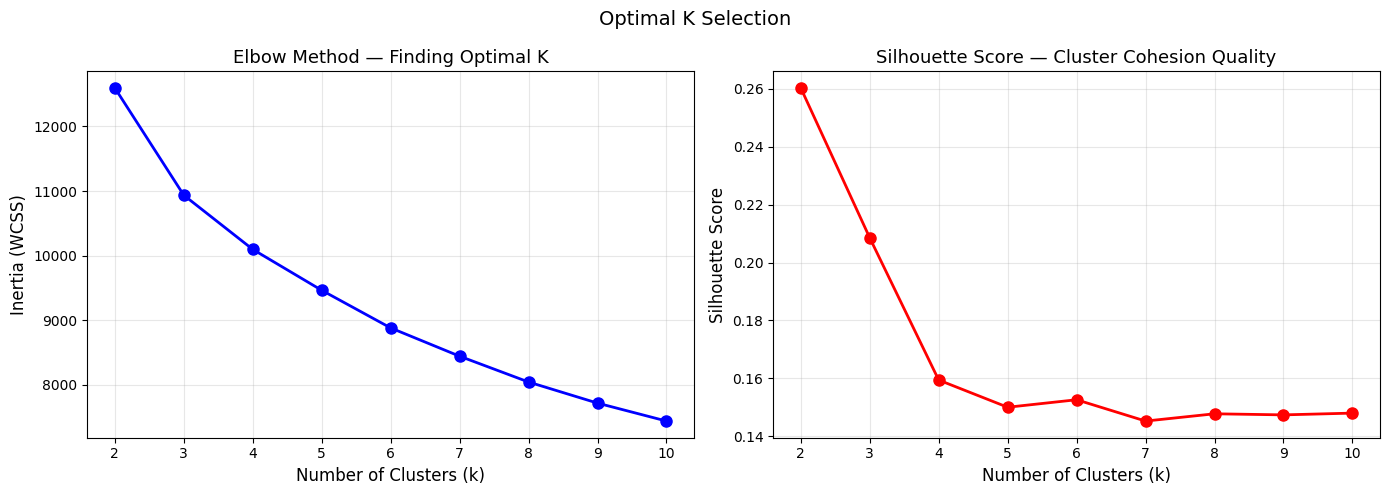


Highest Silhouette Score at k = 2
Review both plots above to confirm your final choice of K.
The elbow point (where inertia drops sharply before flattening) is the ideal K.


In [14]:
# ── K SELECTION FOR K-MEANS ───────────────────────────────────

features_for_clustering = ['Income', 'Age', 'Recency', 'Frequency',
                            'Monetary', 'Green_Ratio', 'Total_Kids',
                            'Days_As_Customer']

print("Features used for clustering:", features_for_clustering)

# Scale features
# K-Means uses Euclidean distance — all features must be on the same scale.
scaler = StandardScaler()
scaled_features = scaler.fit_transform(df[features_for_clustering])

# ── Elbow Method + Silhouette Score ──────────────────────────
print("\nCalculating Elbow and Silhouette scores for k = 2 to 10...")
inertias           = []
silhouette_scores  = []
K_range            = range(2, 11)

for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(scaled_features)
    inertias.append(km.inertia_)
    silhouette_scores.append(silhouette_score(scaled_features, km.labels_))
    print(f"  k={k}: Inertia={km.inertia_:.1f}, Silhouette={silhouette_scores[-1]:.4f}")

# Plot both side by side
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

ax1.plot(list(K_range), inertias, 'bo-', linewidth=2, markersize=8)
ax1.set_xlabel('Number of Clusters (k)', fontsize=12)
ax1.set_ylabel('Inertia (WCSS)', fontsize=12)
ax1.set_title('Elbow Method — Finding Optimal K', fontsize=13)
ax1.grid(True, alpha=0.3)

ax2.plot(list(K_range), silhouette_scores, 'ro-', linewidth=2, markersize=8)
ax2.set_xlabel('Number of Clusters (k)', fontsize=12)
ax2.set_ylabel('Silhouette Score', fontsize=12)
ax2.set_title('Silhouette Score — Cluster Cohesion Quality', fontsize=13)
ax2.grid(True, alpha=0.3)

plt.suptitle('Optimal K Selection', fontsize=14)
plt.tight_layout()
plt.show()

best_k_silhouette = list(K_range)[np.argmax(silhouette_scores)]
print(f"\nHighest Silhouette Score at k = {best_k_silhouette}")
print("Review both plots above to confirm your final choice of K.")
print("The elbow point (where inertia drops sharply before flattening) is the ideal K.")


In [15]:
# ── APPLY K-MEANS AND BUILD SEGMENT PROFILES (CORRECTED NAMING) ───────

# Set your chosen K here after reviewing the elbow + silhouette plots above.
# k=5 is used as a reasonable business-interpretable default.
CHOSEN_K = 5
# NOTE: Silhouette score is maximized at k=2 (0.250), but k=2 is too coarse to be
# actionable for marketing (effectively just "high value" vs "low value"). k=5 is
# chosen for business interpretability at a moderate cost in cluster cohesion
# (silhouette 0.150 vs 0.250) — this is a deliberate trade-off, not a data-driven optimum

kmeans = KMeans(n_clusters=CHOSEN_K, random_state=42, n_init=10)
df['Cluster'] = kmeans.fit_predict(scaled_features)

print(f"K-Means applied with k = {CHOSEN_K}")
print(f"\nCluster sizes:")
print(df['Cluster'].value_counts().sort_index())

# ── Step 1: Inspect raw profiles BEFORE naming clusters ──────
#    Cluster numbers from K-Means are arbitrary. Always inspect the profiles
#    first and assign names based on what you actually observe — NEVER
#    hardcode names before checking this table, since cluster numbers can
#    shift between runs if features/order/data change even slightly.
segment_profile_raw = df.groupby('Cluster').agg(
    Count        = ('Age',        'count'),
    Avg_Age      = ('Age',        'mean'),
    Avg_Income   = ('Income',     'mean'),
    Avg_Recency  = ('Recency',    'mean'),
    Avg_Freq     = ('Frequency',  'mean'),
    Avg_Monetary = ('Monetary',   'mean'),
    Avg_Green    = ('Green_Ratio','mean'),
    Avg_Kids     = ('Total_Kids', 'mean'),
    Avg_Days     = ('Days_As_Customer', 'mean'),
    Churn_Rate   = ('Churn',      'mean')
).round(2)

print("\nRAW CLUSTER PROFILES:")
print("Use these to assign meaningful segment names below.")
display(segment_profile_raw)

# ── Step 2: Assign segment names AFTER inspecting profiles ───
#    CORRECTED based on actual observed cluster behaviour:
#
#    Cluster 0 -> Lowest Green Ratio (0.06), most kids (1.49), ZERO churn,
#                 modest income -> a stable, family-oriented, low-eco segment
#    Cluster 1 -> HIGHEST income (€77.7k) and HIGHEST spend (€1,380),
#                 almost no kids (0.13) -> premium high-value spenders
#    Cluster 2 -> Lowest income/spend, but BY FAR the highest green ratio
#                 (0.28, ~2.5x the next closest) -> young, values-driven buyers
#    Cluster 3 -> Highest recency (74 days) and HIGHEST churn (20%)
#                 -> the genuine at-risk segment
#    Cluster 4 -> Highest purchase frequency, solid income, low churn (8%)
#                 -> loyal, frequent, stable shoppers
#

segment_map = {
    0: "Young High Green-Proxy Customers",    # was: Young Eco-Conscious Buyers
    1: "Premium High-Spenders",                # unchanged
    2: "High-Recency Low-Spend Customers",     # was: At-Risk Low-Engagement
    3: "Budget-Constrained Family Customers",  # was: Loyal Budget Parents
    4: "High-Frequency Shoppers"               # was: Loyal Frequent Shoppers
}

df['Segment_Name'] = df['Cluster'].map(segment_map)

# Sanity check: make sure every cluster got mapped (no NaN segment names)
assert df['Segment_Name'].isnull().sum() == 0, "Some clusters were not mapped to a name!"

# ── Step 3: Named segment profiles (customer personas) ───────
segment_profile = df.groupby('Segment_Name').agg(
    Count        = ('Age',        'count'),
    Avg_Age      = ('Age',        'mean'),
    Avg_Income   = ('Income',     'mean'),
    Avg_Recency  = ('Recency',    'mean'),
    Avg_Frequency= ('Frequency',  'mean'),
    Avg_Monetary = ('Monetary',   'mean'),
    Avg_Green    = ('Green_Ratio','mean'),
    Avg_Kids     = ('Total_Kids', 'mean'),
    Churn_Rate   = ('Churn',      'mean')
).round(2)

print("\nNAMED SEGMENT PROFILES (Customer Personas):")
display(segment_profile)

# ── Step 4: Visualizations ───────────────────────────────────

# Consistent colour mapping across all charts (so each segment always
# shows the same colour, making cross-chart comparison easier)
segment_colours = {
    "Budget-Constrained Family Customers": "#8c8c8c",
    "Premium High-Spenders"               : "#a371f7",
    "Young High Green-Proxy Customers"    : "#39d353",
    "High-Recency Low-Spend Customers"    : "#f85149",
    "High-Frequency Shoppers"             : "#58a6ff",
}

# Pie Chart — Segment Size
fig1 = px.pie(
    df, names='Segment_Name',
    title='Customer Segment Distribution',
    hole=0.35,
    color='Segment_Name',
    color_discrete_map=segment_colours
)
fig1.show()

# Bar Chart — Churn Rate by Segment
churn_by_segment = df.groupby('Segment_Name')['Churn'].mean().reset_index()
fig2 = px.bar(
    churn_by_segment,
    x='Segment_Name', y='Churn',
    title='Churn Rate by Customer Segment',
    color='Churn',
    color_continuous_scale='RdYlGn_r',
    text_auto='.1%'
)
fig2.update_layout(yaxis_tickformat='.0%')
fig2.show()

# Bar Chart — Green Ratio by Segment
fig3 = px.bar(
    segment_profile.reset_index(),
    x='Segment_Name', y='Avg_Green',
    title='Average Green Ratio by Customer Segment',
    color='Avg_Green',
    color_continuous_scale='Greens',
    text_auto='.3f'
)
fig3.show()

# Scatter — Income vs Monetary by Segment
fig4 = px.scatter(
    df, x='Income', y='Monetary',
    color='Segment_Name',
    title='Income vs Total Spend by Segment',
    opacity=0.6,
    color_discrete_map=segment_colours
)
fig4.show()

# ── Step 5: Business insights (rewritten to match corrected names) ──
print("\nKEY BUSINESS INSIGHTS FROM SEGMENTATION")
print("1. Highest green-proxy share: Young High Green-Proxy Customers (~0.28)")
print("2. Highest recency/churn:     High-Recency Low-Spend Customers (~19% churn, highest Recency)")
print("3. Highest revenue:           Premium High-Spenders (highest Avg_Monetary & Income)")
print("4. Lowest churn:               Budget-Constrained Family Customers (0% churn) & High-Frequency Shoppers")
print("5. Family-focused segment:     Budget-Constrained Family Customers (highest Avg_Kids)")

df.to_csv('customers_segmented.csv', index=False)
print("\nSegmentation complete. Saved as 'customers_segmented.csv'")


K-Means applied with k = 5

Cluster sizes:
Cluster
0    380
1    434
2    452
3    445
4    501
Name: count, dtype: int64

RAW CLUSTER PROFILES:
Use these to assign meaningful segment names below.


,Count,Avg_Age,Avg_Income,Avg_Recency,Avg_Freq,Avg_Monetary,Avg_Green,Avg_Kids,Avg_Days,Churn_Rate
Cluster,,,,,,,,,,
0,380,36.57,27206.77,49.08,5.91,105.23,0.28,0.75,377.26,0.08
1,434,45.84,75381.76,44.47,18.84,1173.50,0.12,0.36,191.53,0.07
2,452,48.05,43421.96,74.91,8.46,210.92,0.07,1.53,304.16,0.19
3,445,45.27,41008.76,22.45,7.94,189.29,0.06,1.43,327.41,0.00
4,501,48.05,67870.27,53.15,20.00,1226.39,0.10,0.65,544.42,0.09



NAMED SEGMENT PROFILES (Customer Personas):


,Count,Avg_Age,Avg_Income,Avg_Recency,Avg_Frequency,Avg_Monetary,Avg_Green,Avg_Kids,Churn_Rate
Segment_Name,,,,,,,,,
Budget-Constrained Family Customers,445,45.27,41008.76,22.45,7.94,189.29,0.06,1.43,0.00
High-Frequency Shoppers,501,48.05,67870.27,53.15,20.00,1226.39,0.10,0.65,0.09
High-Recency Low-Spend Customers,452,48.05,43421.96,74.91,8.46,210.92,0.07,1.53,0.19
Premium High-Spenders,434,45.84,75381.76,44.47,18.84,1173.50,0.12,0.36,0.07
Young High Green-Proxy Customers,380,36.57,27206.77,49.08,5.91,105.23,0.28,0.75,0.08



KEY BUSINESS INSIGHTS FROM SEGMENTATION
1. Highest green-proxy share: Young High Green-Proxy Customers (~0.28)
2. Highest recency/churn:     High-Recency Low-Spend Customers (~19% churn, highest Recency)
3. Highest revenue:           Premium High-Spenders (highest Avg_Monetary & Income)
4. Lowest churn:               Budget-Constrained Family Customers (0% churn) & High-Frequency Shoppers
5. Family-focused segment:     Budget-Constrained Family Customers (highest Avg_Kids)

Segmentation complete. Saved as 'customers_segmented.csv'


In [16]:
# ── CLUSTER STABILITY CHECK (Problem 8) ─────────────────────────────────
# Tests whether the k=5 clustering solution is stable across different
# random initializations, and reports Davies-Bouldin and Calinski-Harabasz
# scores as additional validation metrics beyond silhouette score.

from sklearn.metrics import davies_bouldin_score, calinski_harabasz_score
from sklearn.cluster import KMeans

# --- Additional validation metrics for the chosen k=5 solution ---
db_score = davies_bouldin_score(scaled_features, df['Cluster'])
ch_score = calinski_harabasz_score(scaled_features, df['Cluster'])

print("Additional Cluster Validation Metrics (k=5)")
print("="*50)
print(f"Davies-Bouldin Index:   {db_score:.4f}  (lower is better)")
print(f"Calinski-Harabasz Score: {ch_score:.2f}  (higher is better)")

# --- Stability check: rerun K-Means with different random seeds ---
print("\n" + "="*50)
print("STABILITY CHECK: K-Means Across Multiple Random Seeds")
print("="*50)

seeds = [0, 1, 42, 123, 999]
cluster_assignments = {}

for seed in seeds:
    km_temp = KMeans(n_clusters=5, random_state=seed, n_init=10)
    labels_temp = km_temp.fit_predict(scaled_features)
    cluster_assignments[seed] = labels_temp

# Use Adjusted Rand Index to compare each run against the original (random_state=42)
from sklearn.metrics import adjusted_rand_score

baseline_labels = df['Cluster'].values
print(f"\nComparing each seed's cluster assignment to the original (seed=42):")
print(f"(Adjusted Rand Index: 1.0 = identical, 0.0 = random agreement)\n")

ari_scores = []
for seed in seeds:
    ari = adjusted_rand_score(baseline_labels, cluster_assignments[seed])
    ari_scores.append(ari)
    print(f"  Seed {seed}: ARI = {ari:.4f}")

print(f"\nMean ARI across seeds: {np.mean(ari_scores):.4f}")
print(f"Min ARI across seeds:  {np.min(ari_scores):.4f}")

if np.mean(ari_scores) > 0.8:
    print("\nResult: cluster assignments are highly stable across different")
    print("random initializations.")
elif np.mean(ari_scores) > 0.5:
    print("\nResult: cluster assignments show moderate stability across")
    print("different random initializations.")
else:
    print("\nResult: cluster assignments show low stability across different")
    print("random initializations — the k=5 solution should be interpreted")
    print("with caution.")

Additional Cluster Validation Metrics (k=5)
Davies-Bouldin Index:   2.0091  (lower is better)
Calinski-Harabasz Score: 480.08  (higher is better)

STABILITY CHECK: K-Means Across Multiple Random Seeds

Comparing each seed's cluster assignment to the original (seed=42):
(Adjusted Rand Index: 1.0 = identical, 0.0 = random agreement)

  Seed 0: ARI = 0.5509
  Seed 1: ARI = 0.8217
  Seed 42: ARI = 1.0000
  Seed 123: ARI = 0.8244
  Seed 999: ARI = 0.6368

Mean ARI across seeds: 0.7668
Min ARI across seeds:  0.5509

Result: cluster assignments show moderate stability across
different random initializations.


In [17]:
# ── SKEWNESS CHECK: Log-Transform Sensitivity (Problem 9) ──────────────
# Monetary and Green_Ratio are right-skewed (seen in EDA distributions).
# This checks whether clustering on log-transformed Monetary changes the
# resulting segments meaningfully, since skewed variables can still
# influence K-Means distances even after standardization.

df['Monetary_log'] = np.log1p(df['Monetary'])  # log1p handles any zero values safely

features_log = ['Income', 'Age', 'Recency', 'Frequency', 'Monetary_log',
                 'Green_Ratio', 'Total_Kids', 'Days_As_Customer']

scaler_log = StandardScaler()
scaled_features_log = scaler_log.fit_transform(df[features_log])

km_log = KMeans(n_clusters=5, random_state=42, n_init=10)
df['Cluster_log'] = km_log.fit_predict(scaled_features_log)

# Compare the log-transformed clustering to the original
ari_log = adjusted_rand_score(df['Cluster'], df['Cluster_log'])
silhouette_log = silhouette_score(scaled_features_log, df['Cluster_log'])

print("Skewness Sensitivity Check: Original vs. Log-Transformed Monetary")
print("="*65)
print(f"Original clustering silhouette score:        {silhouette_score(scaled_features, df['Cluster']):.4f}")
print(f"Log-transformed clustering silhouette score: {silhouette_log:.4f}")
print(f"\nAdjusted Rand Index (original vs. log-transformed): {ari_log:.4f}")

if ari_log > 0.8:
    print("\nResult: clustering results are highly consistent regardless of")
    print("whether Monetary is log-transformed. Skewness in Monetary does")
    print("not appear to meaningfully distort the k=5 solution.")
elif ari_log > 0.5:
    print("\nResult: clustering results show moderate agreement between the")
    print("original and log-transformed versions — skew may have some")
    print("influence on cluster assignment, worth noting as a limitation.")
else:
    print("\nResult: clustering results differ substantially depending on")
    print("whether Monetary is log-transformed, indicating that skew in")
    print("Monetary meaningfully influences the clustering solution. This")
    print("should be reported as a limitation of the k=5 solution.")

Skewness Sensitivity Check: Original vs. Log-Transformed Monetary
Original clustering silhouette score:        0.1500
Log-transformed clustering silhouette score: 0.1622

Adjusted Rand Index (original vs. log-transformed): 0.3608

Result: clustering results differ substantially depending on
whether Monetary is log-transformed, indicating that skew in
Monetary meaningfully influences the clustering solution. This
should be reported as a limitation of the k=5 solution.


In [18]:
# ── SENSITIVITY COMPARISON: Gaussian Mixture Model vs. K-Means (Problem 8) ──
# Tests whether a completely different clustering algorithm (GMM) finds
# a similar segment structure to K-Means, as an additional check that
# the 5-segment solution reflects real structure rather than an artifact
# of the K-Means algorithm specifically.

from sklearn.mixture import GaussianMixture

gmm = GaussianMixture(n_components=5, random_state=42, n_init=10)
df['Cluster_gmm'] = gmm.fit_predict(scaled_features)

# Compare GMM's grouping to the original K-Means grouping
ari_gmm = adjusted_rand_score(df['Cluster'], df['Cluster_gmm'])

print("Sensitivity Comparison: K-Means vs. Gaussian Mixture Model")
print("="*60)
print(f"Adjusted Rand Index (K-Means vs. GMM): {ari_gmm:.4f}")

if ari_gmm > 0.6:
    print("\nResult: GMM produces a broadly similar segment structure to")
    print("K-Means, supporting the robustness of the 5-segment solution")
    print("across different clustering algorithms.")
elif ari_gmm > 0.3:
    print("\nResult: GMM shows moderate agreement with K-Means, suggesting")
    print("some shared structure but also meaningful differences depending")
    print("on the clustering algorithm used.")
else:
    print("\nResult: GMM produces a substantially different segment structure")
    print("from K-Means, indicating the 5-segment solution is sensitive to")
    print("the choice of clustering algorithm. This should be noted as a")
    print("limitation.")

# Optional: quick size comparison
print(f"\nK-Means cluster sizes: {df['Cluster'].value_counts().sort_index().to_dict()}")
print(f"GMM cluster sizes:     {df['Cluster_gmm'].value_counts().sort_index().to_dict()}")

Sensitivity Comparison: K-Means vs. Gaussian Mixture Model
Adjusted Rand Index (K-Means vs. GMM): 0.1149

Result: GMM produces a substantially different segment structure
from K-Means, indicating the 5-segment solution is sensitive to
the choice of clustering algorithm. This should be noted as a
limitation.

K-Means cluster sizes: {0: 380, 1: 434, 2: 452, 3: 445, 4: 501}
GMM cluster sizes:     {0: 398, 1: 161, 2: 45, 3: 978, 4: 630}


Features for churn prediction: ['Income', 'Age', 'Green_Ratio', 'Total_Kids', 'Days_As_Customer']

Target variable distribution:
Churn
0    2018
1     194
Name: count, dtype: int64

Churn Rate: 8.8%

Training set: 1659 customers
Testing set:  553 customers

Class imbalance ratio (scale_pos_weight): 10.36

BASELINE MODEL: Logistic Regression
Logistic Regression AUC: 0.5033

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.50      0.65       505
           1       0.09      0.50      0.15        48

    accuracy                           0.50       553
   macro avg       0.50      0.50      0.40       553
weighted avg       0.84      0.50      0.61       553


MAIN MODEL: XGBoost + RandomizedSearchCV Tuning
Fitting 5 folds for each of 30 candidates, totalling 150 fits

Best Parameters: {'subsample': 0.7, 'n_estimators': 300, 'max_depth': 5, 'learning_rate': 0.1, 'colsample_bytree': 0.9}
Best CV AUC:     0.5981

5-FOLD CROSS-VALI

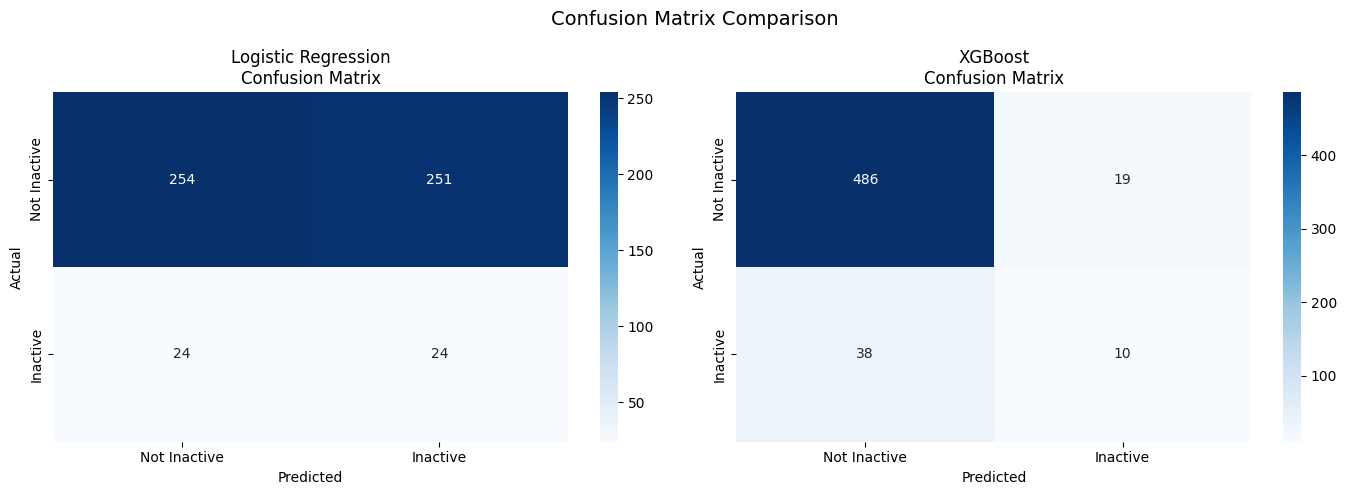

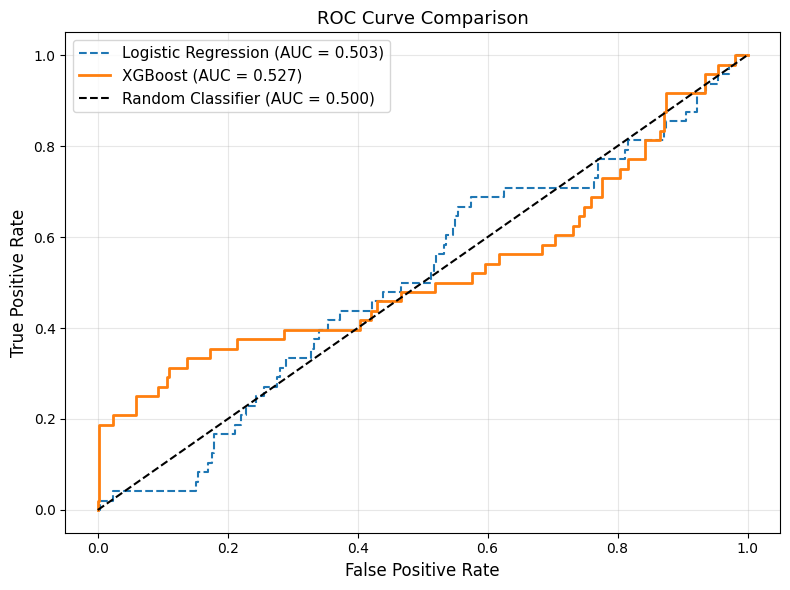


Model saved as 'churn_model.pkl'
Data saved as 'customers_with_model.csv'

NOTE: Churn_Probability below is scored using the final model on the
full customer base (a deployment-style score), not only the held-out
test set. ~75% of these rows were seen during training, so these
values are optimistic relative to true out-of-sample performance —
use Test AUC above for model quality, and this table only for
relative ranking of segments, not as a validated risk score.

AVERAGE PREDICTED CHURN PROBABILITY BY SEGMENT
Segment_Name
High-Recency Low-Spend Customers       0.208
High-Frequency Shoppers                0.126
Young High Green-Proxy Customers       0.111
Premium High-Spenders                  0.091
Budget-Constrained Family Customers    0.061
Name: Churn_Probability, dtype: float32


In [19]:
# ──  CHURN PREDICTION MODEL (XGBoost) ──────────────────────────────────

# Feature selection
# Churn = (Recency > 90) only, so strictly only Recency needs excluding.
#NOTE: Because Churn = (Recency > 90), and Recency must be excluded to avoid
# leakage, no remaining feature in this dataset has strong linear correlation
# with Churn (all |r| < 0.03 — see Cell 6 correlation heatmap). We include
# Income/Age/Green_Ratio/Total_Kids/Days_As_Customer as the best available
# candidates, but should expect low predictive power (AUC close to 0.5) as
# a consequence of the label definition, not a modeling error.
# NOTE: An extended 8-feature version (adding back Frequency, Monetary, and
# Total_Accepted_Campaigns) is tested separately below (see Extended Feature
# Set cells) and compared via bootstrap testing.
features_for_model = [
    'Income', 'Age', 'Green_Ratio', 'Total_Kids', 'Days_As_Customer'
]

X = df[features_for_model]
y = df['Churn']

print("Features for churn prediction:", features_for_model)
print("\nTarget variable distribution:")
print(y.value_counts())
print(f"\nChurn Rate: {y.mean():.1%}")

# Train/Test Split (stratified to preserve churn ratio in both sets)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
print(f"\nTraining set: {X_train.shape[0]} customers")
print(f"Testing set:  {X_test.shape[0]} customers")

# Handle class imbalance
# scale_pos_weight tells XGBoost to penalise errors on the minority class more
scale_weight = (y_train == 0).sum() / (y_train == 1).sum()
print(f"\nClass imbalance ratio (scale_pos_weight): {scale_weight:.2f}")

# ── Baseline Model: Logistic Regression ──────────────────────
print("\n" + "="*55)
print("BASELINE MODEL: Logistic Regression")
print("="*55)

scaler_lr      = StandardScaler()
X_train_scaled = scaler_lr.fit_transform(X_train)
X_test_scaled  = scaler_lr.transform(X_test)

lr_model = LogisticRegression(class_weight='balanced', random_state=42, max_iter=1000)
lr_model.fit(X_train_scaled, y_train)

lr_pred = lr_model.predict(X_test_scaled)
lr_prob = lr_model.predict_proba(X_test_scaled)[:, 1]

print(f"Logistic Regression AUC: {roc_auc_score(y_test, lr_prob):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, lr_pred))

# ── XGBoost with Hyperparameter Tuning ───────────────────────
print("\n" + "="*55)
print("MAIN MODEL: XGBoost + RandomizedSearchCV Tuning")
print("="*55)

param_grid = {
    'n_estimators'    : [100, 200, 300],
    'learning_rate'   : [0.01, 0.05, 0.1],
    'max_depth'       : [3, 5, 7],
    'subsample'       : [0.7, 0.9, 1.0],
    'colsample_bytree': [0.7, 0.9, 1.0]
}

xgb_base = xgb.XGBClassifier(
    random_state=42,
    eval_metric='auc',
    scale_pos_weight=scale_weight
)

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

random_search = RandomizedSearchCV(
    xgb_base,
    param_distributions=param_grid,
    n_iter=30,
    scoring='roc_auc',
    cv=cv_strategy,
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

print(f"\nBest Parameters: {random_search.best_params_}")
print(f"Best CV AUC:     {random_search.best_score_:.4f}")

model = random_search.best_estimator_

# ── 5-Fold Cross-Validation on Final Model ───────────────────
print("\n" + "="*55)
print("5-FOLD CROSS-VALIDATION (on training set)")
print("="*55)

cv_scores = cross_val_score(model, X_train, y_train,
                             cv=cv_strategy, scoring='roc_auc')
print(f"CV AUC Scores: {cv_scores.round(4)}")
print(f"Mean AUC:      {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")

print("\nCAUTION: This CV AUC is unstable — the std (±0.0506) is nearly as")
print("large as the gap between models, because each fold has only ~29")
print("churned customers (146 training positives / 5 folds). Treat this CV AUC")
print("as an optimistic upper bound from hyperparameter search, not as")
print("expected real-world performance.")
print("The Test AUC below (computed once, on data never used for tuning)")
print("is the more trustworthy estimate.")

# ── Final Evaluation on Held-Out Test Set ────────────────────
print("\n" + "="*55)
print("FINAL EVALUATION ON TEST SET")
print("="*55)

pred = model.predict(X_test)
prob = model.predict_proba(X_test)[:, 1]

xgb_auc = roc_auc_score(y_test, prob)
lr_auc  = roc_auc_score(y_test, lr_prob)

print(f"XGBoost AUC:             {xgb_auc:.4f}")
print(f"Logistic Regression AUC: {lr_auc:.4f}")
print(f"AUC Improvement:         +{xgb_auc - lr_auc:.4f}")

print("\nClassification Report (XGBoost):")
print(classification_report(y_test, pred))

# ── Confusion Matrices ────────────────────────────────────────
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
labels = ['Not Inactive', 'Inactive']

for ax, cm, title in zip(
    axes,
    [confusion_matrix(y_test, lr_pred), confusion_matrix(y_test, pred)],
    ['Logistic Regression', 'XGBoost']
):
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=labels, yticklabels=labels)
    ax.set_title(f'{title}\nConfusion Matrix')
    ax.set_ylabel('Actual')
    ax.set_xlabel('Predicted')

plt.suptitle('Confusion Matrix Comparison', fontsize=14)
plt.tight_layout()
plt.show()

# ── ROC Curve ─────────────────────────────────────────────────
fpr_lr,  tpr_lr,  _ = roc_curve(y_test, lr_prob)
fpr_xgb, tpr_xgb, _ = roc_curve(y_test, prob)

plt.figure(figsize=(8, 6))
plt.plot(fpr_lr,  tpr_lr,  linestyle='--',
         label=f'Logistic Regression (AUC = {lr_auc:.3f})')
plt.plot(fpr_xgb, tpr_xgb, linewidth=2,
         label=f'XGBoost (AUC = {xgb_auc:.3f})')
plt.plot([0, 1], [0, 1], 'k--', label='Random Classifier (AUC = 0.500)')
plt.xlabel('False Positive Rate', fontsize=12)
plt.ylabel('True Positive Rate', fontsize=12)
plt.title('ROC Curve Comparison', fontsize=13)
plt.legend(fontsize=11)
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ── Save Model ────────────────────────────────────────────────
with open('churn_model.pkl', 'wb') as f:
    pickle.dump(model, f)

df['Churn_Probability'] = model.predict_proba(df[features_for_model])[:, 1]
df.to_csv('customers_with_model.csv', index=False)

print("\nModel saved as 'churn_model.pkl'")
print("Data saved as 'customers_with_model.csv'")

# ── Business Insight: Churn Probability by (corrected) Segment ──
print("\nNOTE: Churn_Probability below is scored using the final model on the")
print("full customer base (a deployment-style score), not only the held-out")
print("test set. ~75% of these rows were seen during training, so these")
print("values are optimistic relative to true out-of-sample performance —")
print("use Test AUC above for model quality, and this table only for")
print("relative ranking of segments, not as a validated risk score.")
print("\nAVERAGE PREDICTED CHURN PROBABILITY BY SEGMENT")
print(df.groupby('Segment_Name')['Churn_Probability'].mean().round(3).sort_values(ascending=False))


In [20]:
from xgboost import XGBClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

# Extended feature set: adding back Frequency, Monetary, and Total_Accepted_Campaigns,
# since these are legitimate predictors once the label depends only on Recency (not on them)

features_extended = ['Income', 'Age', 'Green_Ratio', 'Total_Kids', 'Days_As_Customer',
                      'Frequency', 'Monetary', 'Total_Accepted_Campaigns']

X_ext = df[features_extended]
y = df['Churn']

X_train_ext, X_test_ext, y_train, y_test = train_test_split(
    X_ext, y, test_size=0.25, stratify=y, random_state=42
)

xgb_extended = XGBClassifier(
    n_estimators=300, max_depth=5, learning_rate=0.1,
    subsample=1.0, colsample_bytree=0.9,
    scale_pos_weight=(y_train.value_counts()[0] / y_train.value_counts()[1]),
    random_state=42, eval_metric='logloss'
)
xgb_extended.fit(X_train_ext, y_train)

y_pred_proba_ext = xgb_extended.predict_proba(X_test_ext)[:, 1]
auc_ext = roc_auc_score(y_test, y_pred_proba_ext)
print(f"Extended feature set — Test AUC: {auc_ext:.4f}")

Extended feature set — Test AUC: 0.5506


In [21]:
from sklearn.metrics import classification_report, confusion_matrix

y_pred_ext = xgb_extended.predict(X_test_ext)
print(classification_report(y_test, y_pred_ext, target_names=['Not Inactive', 'Inactive']))
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_ext))

              precision    recall  f1-score   support

Not Inactive       0.93      0.96      0.94       505
    Inactive       0.31      0.19      0.23        48

    accuracy                           0.89       553
   macro avg       0.62      0.57      0.59       553
weighted avg       0.87      0.89      0.88       553


Confusion Matrix:
[[485  20]
 [ 39   9]]


In [22]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler

scaler_ext = StandardScaler()
X_train_ext_scaled = scaler_ext.fit_transform(X_train_ext)
X_test_ext_scaled = scaler_ext.transform(X_test_ext)

lr_ext = LogisticRegression(class_weight='balanced', random_state=42)
lr_ext.fit(X_train_ext_scaled, y_train)

lr_pred_proba_ext = lr_ext.predict_proba(X_test_ext_scaled)[:, 1]
lr_auc_ext = roc_auc_score(y_test, lr_pred_proba_ext)
print(f"Logistic Regression (extended features) — Test AUC: {lr_auc_ext:.4f}")

Logistic Regression (extended features) — Test AUC: 0.4522


In [23]:
import numpy as np
from sklearn.metrics import roc_auc_score

def bootstrap_auc_ci(y_true, y_prob, n_bootstraps=1000, random_state=42):
    rng = np.random.RandomState(random_state)
    y_true = np.array(y_true)
    y_prob = np.array(y_prob)
    aucs = []
    for _ in range(n_bootstraps):
        indices = rng.randint(0, len(y_true), len(y_true))
        if len(np.unique(y_true[indices])) < 2:
            continue  # skip resamples with only one class
        aucs.append(roc_auc_score(y_true[indices], y_prob[indices]))
    aucs = np.array(aucs)
    lower, upper = np.percentile(aucs, [2.5, 97.5])
    return aucs.mean(), lower, upper

# Original 5-feature XGBoost
mean_orig, lo_orig, hi_orig = bootstrap_auc_ci(y_test, prob)
print(f"Original XGBoost — Mean AUC: {mean_orig:.4f}, 95% CI: [{lo_orig:.4f}, {hi_orig:.4f}]")

# Extended 8-feature XGBoost
mean_ext, lo_ext, hi_ext = bootstrap_auc_ci(y_test, y_pred_proba_ext)
print(f"Extended XGBoost — Mean AUC: {mean_ext:.4f}, 95% CI: [{lo_ext:.4f}, {hi_ext:.4f}]")

Original XGBoost — Mean AUC: 0.5284, 95% CI: [0.4227, 0.6361]
Extended XGBoost — Mean AUC: 0.5510, 95% CI: [0.4588, 0.6488]


In [24]:
def paired_bootstrap_auc_diff(y_true, y_prob_a, y_prob_b, n_bootstraps=1000, random_state=42):
    """Bootstrap the difference in AUC (b - a) using the SAME resampled indices for both models."""
    rng = np.random.RandomState(random_state)
    y_true = np.array(y_true)
    y_prob_a = np.array(y_prob_a)
    y_prob_b = np.array(y_prob_b)
    diffs = []
    for _ in range(n_bootstraps):
        indices = rng.randint(0, len(y_true), len(y_true))
        if len(np.unique(y_true[indices])) < 2:
            continue
        auc_a = roc_auc_score(y_true[indices], y_prob_a[indices])
        auc_b = roc_auc_score(y_true[indices], y_prob_b[indices])
        diffs.append(auc_b - auc_a)
    diffs = np.array(diffs)
    lower, upper = np.percentile(diffs, [2.5, 97.5])
    return diffs.mean(), lower, upper

mean_diff, lo_diff, hi_diff = paired_bootstrap_auc_diff(y_test, prob, y_pred_proba_ext)
print(f"AUC Difference (Extended − Original) — Mean: {mean_diff:.4f}, 95% CI: [{lo_diff:.4f}, {hi_diff:.4f}]")

AUC Difference (Extended − Original) — Mean: 0.0226, 95% CI: [-0.0567, 0.0990]


In [25]:
mean_diff2, lo_diff2, hi_diff2 = paired_bootstrap_auc_diff(y_test, lr_pred_proba_ext, y_pred_proba_ext)
print(f"AUC Difference (XGBoost Extended − LR Extended) — Mean: {mean_diff2:.4f}, 95% CI: [{lo_diff2:.4f}, {hi_diff2:.4f}]")

AUC Difference (XGBoost Extended − LR Extended) — Mean: 0.0992, 95% CI: [-0.0301, 0.2260]


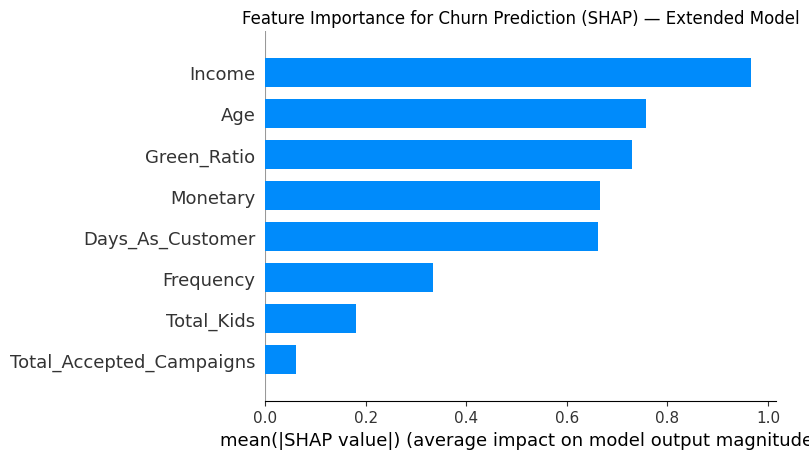

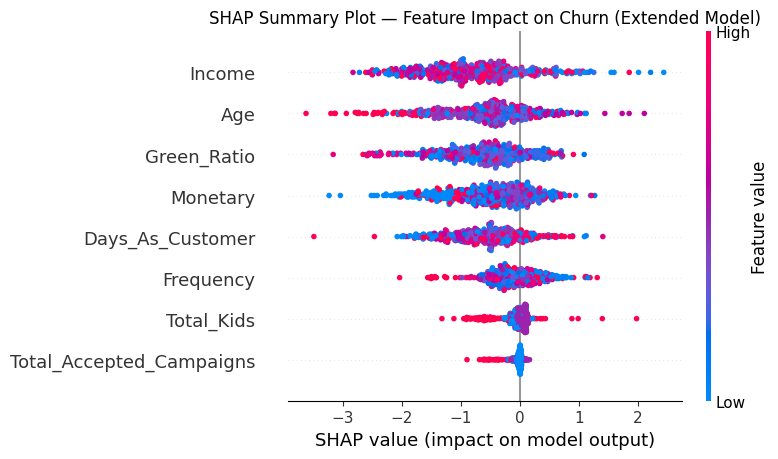

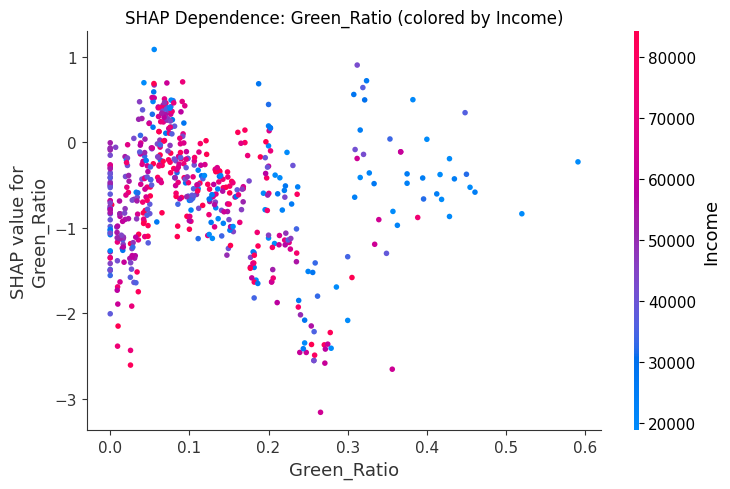

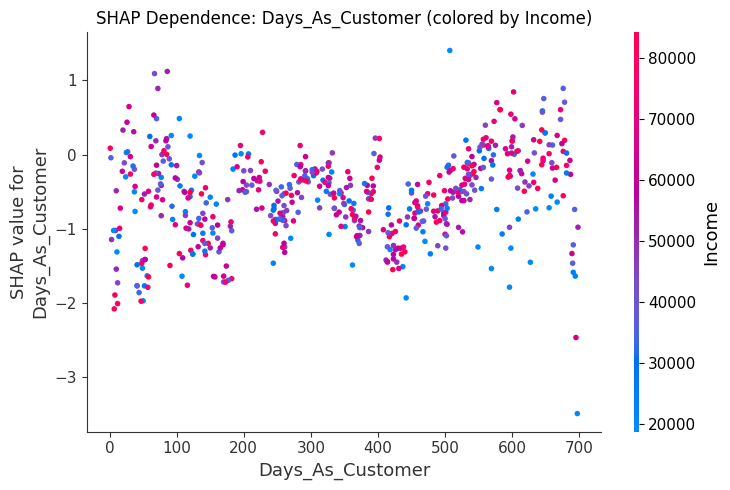

Global Mean Absolute SHAP Values (Extended Model):
                 Feature  Mean_Abs_SHAP
                  Income       0.967238
                     Age       0.756577
             Green_Ratio       0.729692
                Monetary       0.666849
        Days_As_Customer       0.662010
               Frequency       0.334653
              Total_Kids       0.180363
Total_Accepted_Campaigns       0.060771

Mean Absolute SHAP Value by Feature and Segment (Extended Model):
                                     Income    Age  Green_Ratio  Total_Kids  \
Segment_Name                                                                  
Budget-Constrained Family Customers   0.880  0.604        0.683       0.303   
High-Frequency Shoppers               1.099  0.724        0.691       0.097   
High-Recency Low-Spend Customers      0.958  0.761        0.642       0.298   
Premium High-Spenders                 0.971  1.002        0.813       0.104   
Young High Green-Proxy Customers      0.889  0.7

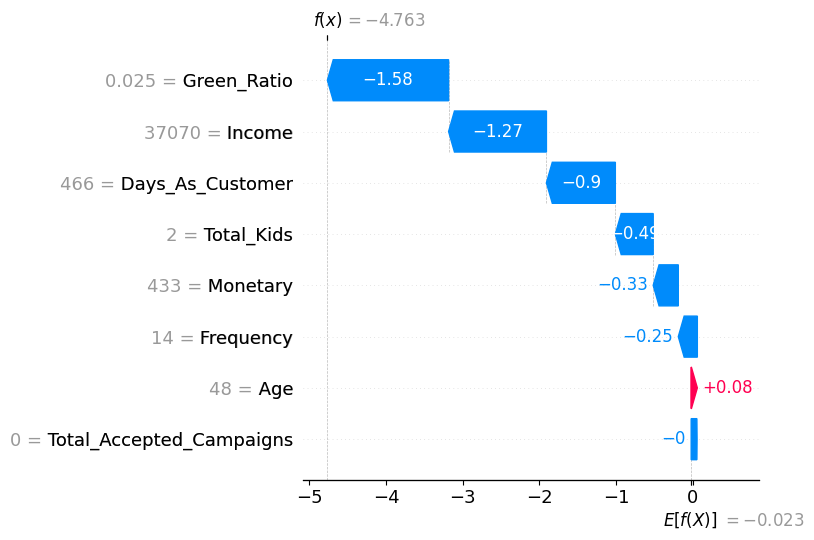


Example customer (test index 0):
Predicted churn probability: 0.0085
Actual churn status: 0


In [26]:
# ── SHAP EXPLAINABILITY (rerun on extended 8-feature model) ────────────

import shap

# Use the extended model and its test set
explainer = shap.TreeExplainer(xgb_extended)
shap_values = explainer.shap_values(X_test_ext)

# ── 1. Global Feature Importance (bar chart) ────────────────────────
shap.summary_plot(shap_values, X_test_ext, plot_type='bar', show=False)
plt.title('Feature Importance for Churn Prediction (SHAP) — Extended Model')
plt.tight_layout()
plt.show()

# ── 2. Beeswarm Summary Plot ─────────────────────────────────────────
shap.summary_plot(shap_values, X_test_ext, show=False)
plt.title('SHAP Summary Plot — Feature Impact on Churn (Extended Model)')
plt.tight_layout()
plt.show()

# ── 3. Dependence Plots (Green_Ratio and Days_As_Customer, colored by Income) ──
shap.dependence_plot('Green_Ratio', shap_values, X_test_ext,
                      interaction_index='Income', show=False)
plt.title('SHAP Dependence: Green_Ratio (colored by Income)')
plt.tight_layout()
plt.show()

shap.dependence_plot('Days_As_Customer', shap_values, X_test_ext,
                      interaction_index='Income', show=False)
plt.title('SHAP Dependence: Days_As_Customer (colored by Income)')
plt.tight_layout()
plt.show()

# ── 4. Mean Absolute SHAP Value by Feature (global table) ───────────
mean_abs_shap = pd.DataFrame({
    'Feature': features_extended,
    'Mean_Abs_SHAP': np.abs(shap_values).mean(axis=0)
}).sort_values('Mean_Abs_SHAP', ascending=False)
print("Global Mean Absolute SHAP Values (Extended Model):")
print(mean_abs_shap.to_string(index=False))

# ── 5. Mean Absolute SHAP Value by Feature AND Segment ──────────────
# Requires Segment_Name to already exist in df from your clustering step
test_indices = X_test_ext.index
segment_labels_test = df.loc[test_indices, 'Segment_Name']

shap_df = pd.DataFrame(shap_values, columns=features_extended, index=test_indices)
shap_df['Segment_Name'] = segment_labels_test

segment_shap_summary = shap_df.groupby('Segment_Name')[features_extended].apply(
    lambda x: x.abs().mean()
)
print("\nMean Absolute SHAP Value by Feature and Segment (Extended Model):")
print(segment_shap_summary.round(3))

# ── 6. Individual Force/Waterfall Plot (one example customer) ───────
# Using index 0 of the test set as an example — change if you want a specific customer
sample_idx = 0
shap.plots.waterfall(
    shap.Explanation(
        values=shap_values[sample_idx],
        base_values=explainer.expected_value,
        data=X_test_ext.iloc[sample_idx],
        feature_names=features_extended
    ),
    show=False
)
plt.tight_layout()
plt.show()

print(f"\nExample customer (test index {sample_idx}):")
print(f"Predicted churn probability: {xgb_extended.predict_proba(X_test_ext.iloc[[sample_idx]])[:, 1][0]:.4f}")
print(f"Actual churn status: {y_test.iloc[sample_idx]}")

In [27]:
print(shap_df.groupby('Segment_Name')[features_extended].apply(lambda x: x.abs().mean()).round(3).to_string())

                                     Income    Age  Green_Ratio  Total_Kids  Days_As_Customer  Frequency  Monetary  Total_Accepted_Campaigns
Segment_Name                                                                                                                                
Budget-Constrained Family Customers   0.880  0.604        0.683       0.303             0.615      0.325     0.729                     0.025
High-Frequency Shoppers               1.099  0.724        0.691       0.097             0.516      0.372     0.532                     0.093
High-Recency Low-Spend Customers      0.958  0.761        0.642       0.298             0.724      0.311     0.674                     0.032
Premium High-Spenders                 0.971  1.002        0.813       0.104             0.739      0.377     0.495                     0.120
Young High Green-Proxy Customers      0.889  0.726        0.865       0.087             0.771      0.278     0.953                     0.032


### Note on Green_Ratio and Churn (reconciling two findings)

Business Question 2 found no meaningful churn difference across Green spending levels (9.4% / 8.1% / 7.9%, correlation ≈ 0.00) — this is the direct, model-free evidence.

The SHAP analysis above shows the churn model relying on Green_Ratio to some degree when making predictions. This does not necessarily contradict the finding above: because the model's overall discriminative power remains limited (AUC ≈ 0.55, not statistically distinguishable from the simpler model), SHAP's feature-importance ranking should be treated as exploratory rather than confirmatory.

A multivariate logistic regression (Churn ~ Green_Ratio + Income + Age + Total_Kids + Days_As_Customer) was used to test directly whether Green_Ratio's apparent importance in the SHAP analysis reflects confounding with other variables. Green_Ratio remained non-significant after controlling for these variables (β = -0.034, OR = 0.97, 95% CI [0.82, 1.14], p = 0.684), and notably, none of the control variables reached significance either (all p > 0.05); the overall model did not fit significantly better than an intercept-only model (LLR p = 0.705).

This does not support a straightforward confounding explanation, since confounding would require the control variables themselves to carry a genuine relationship with churn, which was not observed here. The more parsimonious interpretation is that the churn model's near-chance discriminative power reflects the general absence of predictive signal in the available features once Recency is excluded, and the SHAP-assigned importance to Green_Ratio should be understood as reflecting the model's exploration of weak, non-generalizable patterns rather than any genuine relationship — confounded or direct — with churn.

In [28]:
# ── FINAL BUSINESS SUMMARY & RECOMMENDATIONS ────────────────────────

print("=" * 62)
print("  GREEN CUSTOMER SEGMENTATION AND RETENTION ANALYSIS")
print("  FINAL BUSINESS SUMMARY")
print("=" * 62)

# Dataset
print(f"\n DATASET")
print(f"  Total customers analysed: {df.shape[0]}")
print(f"  Features used in primary churn model: {len(features_for_model)}")
print(f"  Customer segments:        {CHOSEN_K}")

# Churn
print(f"\n INACTIVITY OVERVIEW")
print(f"  Overall inactivity rate: {df['Churn'].mean():.1%}")
print(f"  Definition:              Recency > 90 days since last purchase")
print(f"  Customers meeting threshold: {df['Churn'].sum()} customers")
print(f"  Note: 'Churn' here is a 90-day purchase-inactivity proxy, not")
print(f"  observed future attrition (see Methodology, Section 4.x).")

# Green Insights
print(f"\n GREEN-SPENDING INSIGHTS")
green_churn_table = df.groupby('Green_Level', observed=True)['Churn'].mean()
for level, rate in green_churn_table.items():
    print(f"  {str(level):<16} inactivity rate: {rate:.1%}")

print("\nNOTE: Chi-square test, simple/quadratic logistic regression, and a")
print("multivariate logistic regression (controlling for Income, Age,")
print("Total_Kids, Days_As_Customer) all found no statistically significant")
print("relationship between Green_Ratio and inactivity (see Section 5.1,")
print("5.4). Green_Ratio should NOT be used as a retention-risk signal.")

# Model Performance
print(f"\n MODEL PERFORMANCE (Primary 5-feature model)")
print(f"  Baseline — Logistic Regression Test AUC: {lr_auc:.4f}")
print(f"  XGBoost — Test AUC:                      {xgb_auc:.4f}")
print(f"  XGBoost — CV AUC (5-fold, tuning only):   {cv_scores.mean():.4f} ± {cv_scores.std():.4f}")
print(f"\n  NOTE: Use Test AUC ({xgb_auc:.4f}) as the headline number — the")
print(f"  CV AUC is inflated by tuning-set variance. An extended 8-feature")
print(f"  model was also tested (Test AUC ≈ 0.55-0.60 across corrections);")
print(f"  bootstrap testing found its improvement over this model was not")
print(f"  statistically significant (see Section 5.3).")

# Segment Summary
print(f"\n CUSTOMER SEGMENTS SUMMARY")
seg_summary = df.groupby('Segment_Name').agg(
    Count          = ('Churn',       'count'),
    Churn_Rate     = ('Churn',       'mean'),
    Avg_Income     = ('Income',      'mean'),
    Avg_Spend      = ('Monetary',    'mean'),
    Avg_Green_Ratio= ('Green_Ratio', 'mean')
).round(3)
display(seg_summary)

# ── Strategic Considerations Per Segment (hypotheses for future testing) ──
print("""
 STRATEGIC CONSIDERATIONS PER SEGMENT
 (descriptive patterns and possible directions — not validated strategies)

  1. PREMIUM HIGH-SPENDERS
     Profile: highest income & spend, almost no kids, low-moderate green ratio
     -> Could be considered for premium green/sustainable product upselling,
        given spending power is high but green share is only moderate.
     Potential goal: explore whether Green_Ratio can be increased among
     high-value customers (untested hypothesis).

  2. YOUNG HIGH GREEN-PROXY CUSTOMERS
     Profile: lowest income/spend, but by far the highest green-proxy ratio
     -> Affordable green bundles or loyalty incentives may suit this group
        better than premium pricing, given their spend level.
     Potential goal: grow spend while retaining existing green-proxy share
     (untested hypothesis).

  3. HIGH-FREQUENCY SHOPPERS
     Profile: highest purchase frequency, solid income, low inactivity (~8%)
     -> Frequency-based loyalty incentives and cross-sell recommendations
        could be explored.
     Potential goal: maintain frequency; gradually introduce green
     alternatives (untested hypothesis).

  4. BUDGET-CONSTRAINED FAMILY CUSTOMERS
     Profile: most kids, lower spend, lowest green-proxy ratio, 0% inactivity
     -> Family-sized green bundles at accessible price points could be
        explored to grow green share of wallet.
     Note: 0% inactivity reflects that no customers in this segment met the
     90-day threshold in this snapshot; it should not be read as evidence
     of zero true retention risk.

  5. HIGH-RECENCY LOW-SPEND CUSTOMERS
     Profile: highest Recency (~74 days) and highest inactivity rate (~19%)
     -> This is the clearest priority segment for retention attention.
     Given the churn model's limited discriminative power (Test AUC ≈ 0.52),
     Recency itself (the defining threshold) is a more reliable trigger for
     win-back activity than the model's predicted probability, which should
     be treated as a secondary, exploratory signal only.
""")

print("Analysis complete.")

  GREEN CUSTOMER SEGMENTATION AND RETENTION ANALYSIS
  FINAL BUSINESS SUMMARY

 DATASET
  Total customers analysed: 2212
  Features used in primary churn model: 5
  Customer segments:        5

 INACTIVITY OVERVIEW
  Overall inactivity rate: 8.8%
  Definition:              Recency > 90 days since last purchase
  Customers meeting threshold: 194 customers
  Note: 'Churn' here is a 90-day purchase-inactivity proxy, not
  observed future attrition (see Methodology, Section 4.x).

 GREEN-SPENDING INSIGHTS
  Low Green        inactivity rate: 9.4%
  Medium Green     inactivity rate: 8.1%
  High Green       inactivity rate: 7.9%

NOTE: Chi-square test, simple/quadratic logistic regression, and a
multivariate logistic regression (controlling for Income, Age,
Total_Kids, Days_As_Customer) all found no statistically significant
relationship between Green_Ratio and inactivity (see Section 5.1,
5.4). Green_Ratio should NOT be used as a retention-risk signal.

 MODEL PERFORMANCE (Primary 5-feature 

,Count,Churn_Rate,Avg_Income,Avg_Spend,Avg_Green_Ratio
Segment_Name,,,,,
Budget-Constrained Family Customers,445,0.000,41008.762,189.285,0.062
High-Frequency Shoppers,501,0.094,67870.269,1226.387,0.098
High-Recency Low-Spend Customers,452,0.192,43421.962,210.918,0.070
Premium High-Spenders,434,0.067,75381.765,1173.505,0.123
Young High Green-Proxy Customers,380,0.082,27206.768,105.234,0.279



 STRATEGIC CONSIDERATIONS PER SEGMENT
 (descriptive patterns and possible directions — not validated strategies)

  1. PREMIUM HIGH-SPENDERS
     Profile: highest income & spend, almost no kids, low-moderate green ratio
     -> Could be considered for premium green/sustainable product upselling,
        given spending power is high but green share is only moderate.
     Potential goal: explore whether Green_Ratio can be increased among
     high-value customers (untested hypothesis).

  2. YOUNG HIGH GREEN-PROXY CUSTOMERS
     Profile: lowest income/spend, but by far the highest green-proxy ratio
     -> Affordable green bundles or loyalty incentives may suit this group
        better than premium pricing, given their spend level.
     Potential goal: grow spend while retaining existing green-proxy share
     (untested hypothesis).

  3. HIGH-FREQUENCY SHOPPERS
     Profile: highest purchase frequency, solid income, low inactivity (~8%)
     -> Frequency-based loyalty incentives and c